# Segmentación de contratos públicos de SECOP II con MiniBatch K-Means
### Proyecto SEIA · Aprendizaje no supervisado (clustering)

**Contexto.** SEIA es una plataforma para buscar, filtrar y monitorear procesos de contratación pública en SECOP II, y consume el endpoint abierto `jbjy-vk9h` de datos.gov.co (*SECOP II – Contratos Electrónicos*). Este notebook usa **esa misma fuente** para un análisis de aprendizaje no supervisado.

**Problema de segmentación.** Los contratos de SECOP II no traen ninguna etiqueta sobre su "perfil". El objetivo es **descubrir grupos naturales de contratos** a partir de su comportamiento económico y de ejecución:
- cuánto vale el contrato por cada mes de duración;
- cuánto dura;
- qué proporción del valor ya se pagó;
- si fue prorrogado y por cuántos días.

Después se interpreta cada grupo con variables que **no** entraron al modelo: modalidad, tipo de contrato, tipo de contratista, orden, sector, estado y segmento UNSPSC.

**Utilidad para SEIA.** Con esta segmentación un analista puede distinguir de inmediato si un contrato es una prestación de servicios típica, una compra corta con una empresa, un contrato prorrogado o uno sin pagos reportados. También sirve como alerta de seguimiento y para entender el mercado al que apunta el portafolio.

**Restricción del enunciado.** No se usa ninguna variable objetivo ni etiqueta conocida para entrenar. El modelo solo recibe cuatro variables numéricas descriptivas.

| Sección | Contenido |
|---|---|
| 1 | Configuración del entorno |
| 2 | Carga de datos desde la API de datos.gov.co |
| 3 | Exploración de los datos |
| 4 | Preparación: tipos, nulos, duplicados, categóricas, inválidos e ingeniería de variables |
| 5 | Selección de variables y estandarización |
| 6 | Selección y justificación del algoritmo |
| 7 | Determinación del número de clusters |
| 8 | Entrenamiento del modelo final |
| 9 | Evaluación: Silhouette, Davies-Bouldin y Calinski-Harabasz |
| 10 | Visualización de los grupos |
| 11 | Caracterización e interpretación de cada cluster |
| 12 | Limitaciones y posibles errores |
| 13 | Conclusiones |

## 1. Configuración del entorno
Todas las librerías vienen preinstaladas en Google Colab. Se fija una semilla (`SEED = 42`) para que los resultados sean reproducibles.

In [1]:
import io
import os
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans, KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)

SEED = 42
np.random.seed(SEED)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

pandas 2.3.3 | numpy 2.0.2 | scikit-learn 1.6.1


## 2. Carga de datos desde la API de datos.gov.co
**Fuente:** [SECOP II – Contratos Electrónicos](https://www.datos.gov.co/Gastos-Gubernamentales/SECOP-II-Contratos-Electr-nicos/jbjy-vk9h) (`jbjy-vk9h`), el mismo endpoint que consume `seia-services/src/services/secopFetcher.ts`. Hoy tiene más de 5,7 millones de contratos.

**Subconjunto analizado.**
- **Contratos firmados en 2024**: es el último año completo, así que la mayoría de los contratos ya terminó y tiene pagos reportados. Son unos 882.000 contratos.
- **Muestra sistemática del 30 %**: se toman los contratos cuyo `id_contrato` termina en 1, 4 o 7. El último dígito del identificador no tiene relación con el tipo de contrato, así que la muestra queda repartida a lo largo de todo el año y entre todas las entidades, y la descarga sigue siendo razonable: **≈ 267.000 registros**, unos 2 minutos.

**Privacidad.** Solo se descargan columnas de la entidad y del contrato. **No** se descargan nombres, documentos ni datos de contacto de los contratistas.

La descarga usa la API SODA: páginas de 50.000 filas ordenadas por el identificador interno `:id` para que la paginación sea estable, con reintentos automáticos. El resultado se guarda en `datos_secop/` para no descargarlo otra vez si se reejecuta el notebook.

In [2]:
URL_SECOP = 'https://www.datos.gov.co/resource/jbjy-vk9h.csv'
FILTRO_2024_MUESTRA = (
    "fecha_de_firma between '2024-01-01T00:00:00' and '2024-12-31T23:59:59' "
    "AND (id_contrato like '%1' OR id_contrato like '%4' OR id_contrato like '%7')"
)
COLUMNAS = [
    'id_contrato', 'departamento', 'orden', 'sector', 'rama', 'entidad_centralizada',
    'estado_contrato', 'codigo_de_categoria_principal', 'tipo_de_contrato',
    'modalidad_de_contratacion', 'fecha_de_firma', 'fecha_de_inicio_del_contrato',
    'fecha_de_fin_del_contrato', 'tipodocproveedor', 'es_pyme', 'origen_de_los_recursos',
    'destino_gasto', 'valor_del_contrato', 'valor_facturado', 'valor_pagado',
    'valor_pendiente_de_pago', 'dias_adicionados',
]
ARCHIVO_CACHE = os.path.join('datos_secop', 'contratos_2024_muestra_clustering.parquet')


def descargar_secop(columnas, filtro, archivo, tam_pagina=50_000, reintentos=5):
    """Descarga por páginas desde la API SODA de datos.gov.co y guarda una copia local."""
    if os.path.exists(archivo):
        print('Cargando copia local:', archivo)
        return pd.read_parquet(archivo)
    os.makedirs(os.path.dirname(archivo), exist_ok=True)
    paginas, offset, inicio = [], 0, time.time()
    while True:
        params = {'$select': ','.join(columnas), '$where': filtro, '$order': ':id',
                  '$limit': tam_pagina, '$offset': offset}
        for intento in range(1, reintentos + 1):
            try:
                respuesta = requests.get(URL_SECOP, params=params, timeout=300)
                respuesta.raise_for_status()
                break
            except requests.RequestException as error:
                if intento == reintentos:
                    raise
                print(f'  reintento {intento} por error: {error}')
                time.sleep(10 * intento)
        pagina = pd.read_csv(io.StringIO(respuesta.text), dtype=str)
        paginas.append(pagina)
        offset += len(pagina)
        print(f'  {offset:>9,} registros descargados ({time.time() - inicio:,.0f} s)')
        if len(pagina) < tam_pagina:
            break
    datos = pd.concat(paginas, ignore_index=True)
    datos.to_parquet(archivo, index=False)
    return datos


df_raw = descargar_secop(COLUMNAS, FILTRO_2024_MUESTRA, ARCHIVO_CACHE)
print(f'\nDatos: {df_raw.shape[0]:,} registros x {df_raw.shape[1]} columnas')

     50,000 registros descargados (20 s)


    100,000 registros descargados (34 s)


    150,000 registros descargados (59 s)


    200,000 registros descargados (105 s)


    250,000 registros descargados (118 s)


    267,158 registros descargados (133 s)



Datos: 267,158 registros x 22 columnas


In [3]:
df_raw.head(3).T

,0,1,2
id_contrato,CO1.PCCNTR.7072264,CO1.PCCNTR.6984441,CO1.PCCNTR.7069564
departamento,Cundinamarca,Distrito Capital de Bogotá,Valle del Cauca
orden,Territorial,Territorial,Territorial
sector,No aplica/No pertenece,Salud y Protección Social,No aplica/No pertenece
rama,Ejecutivo,Ejecutivo,Ejecutivo
entidad_centralizada,Descentralizada,Centralizada,Centralizada
estado_contrato,terminado,Modificado,En ejecución
codigo_de_categoria_principal,V1.80111701,V1.80111600,V1.80111600
tipo_de_contrato,Prestación de servicios,Prestación de servicios,Prestación de servicios
modalidad_de_contratacion,Contratación directa,Contratación régimen especial,Contratación directa


**Diccionario de las columnas descargadas**

| Columna | Descripción |
|---|---|
| `id_contrato` | Identificador único del contrato en SECOP II |
| `departamento`, `orden`, `sector`, `rama`, `entidad_centralizada` | Datos de la entidad contratante |
| `estado_contrato` | Estado del contrato (en ejecución, cerrado, terminado, modificado…) |
| `codigo_de_categoria_principal` | Código UNSPSC del bien o servicio (`V1.` + 8 dígitos) |
| `tipo_de_contrato` | Prestación de servicios, suministro, compraventa, obra… |
| `modalidad_de_contratacion` | Contratación directa, mínima cuantía, licitación, régimen especial… |
| `fecha_de_firma`, `fecha_de_inicio_del_contrato`, `fecha_de_fin_del_contrato` | Fechas clave |
| `tipodocproveedor` | Documento del contratista: cédula (persona natural) o NIT (persona jurídica) |
| `es_pyme` | Si el contratista es pyme |
| `origen_de_los_recursos`, `destino_gasto` | Fuente del presupuesto e inversión/funcionamiento |
| `valor_del_contrato` | Valor del contrato en pesos colombianos (COP) |
| `valor_facturado`, `valor_pagado`, `valor_pendiente_de_pago` | Ejecución financiera reportada (COP) |
| `dias_adicionados` | Días de prórroga añadidos al plazo inicial |

## 3. Exploración de los datos
### 3.1 Tipos de datos
La API devuelve todo como texto. Por eso, antes de cualquier estadística, hay que convertir los valores a números y las fechas a `datetime`.

In [4]:
df = df_raw.copy()
COLS_VALOR = ['valor_del_contrato', 'valor_facturado', 'valor_pagado', 'valor_pendiente_de_pago', 'dias_adicionados']
COLS_FECHA = ['fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato']
for col in COLS_VALOR:
    df[col] = pd.to_numeric(df[col], errors='coerce')
for col in COLS_FECHA:
    df[col] = pd.to_datetime(df[col], errors='coerce')
df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267158 entries, 0 to 267157
Data columns (total 22 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   id_contrato                    267158 non-null  object        
 1   departamento                   267158 non-null  object        
 2   orden                          267158 non-null  object        
 3   sector                         267158 non-null  object        
 4   rama                           267158 non-null  object        
 5   entidad_centralizada           267158 non-null  object        
 6   estado_contrato                267158 non-null  object        
 7   codigo_de_categoria_principal  267158 non-null  object        
 8   tipo_de_contrato               267158 non-null  object        
 9   modalidad_de_contratacion      267158 non-null  object        
 10  fecha_de_firma                 267158 non-null  datetime64[ns]
 11  

### 3.2 Estadística descriptiva de las variables numéricas

In [5]:
df[COLS_VALOR].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
valor_del_contrato,"267,158.000","24,531,358,810.150","12,486,889,126,951.049",0.000,"956,407.000","9,000,000.000","18,000,000.000","37,016,009.000","1,974,952,918.000","6,453,840,000,000,000.000"
valor_facturado,"267,158.000","68,044,447.655","1,792,458,380.848",0.000,0.000,0.000,"8,726,366.500","24,500,000.000","791,686,808.670","499,999,991,005.000"
valor_pagado,"267,158.000","54,669,587.287","989,656,104.583",0.000,0.000,0.000,"6,907,933.000","22,260,000.000","646,282,817.595","210,317,213,859.000"
valor_pendiente_de_pago,"267,158.000","24,476,697,659.785","12,486,889,171,924.000","-598,321,339.000",0.000,0.000,"1,997,265.000","14,000,000.000","1,096,962,723.360","6,453,840,000,000,000.000"
dias_adicionados,"267,158.000",6.223,28.194,0.000,0.000,0.000,0.000,0.000,102.000,"3,713.000"


- `valor_del_contrato` tiene una **asimetría extrema**. La mediana ronda los 18 millones de COP, pero el máximo llega a billones, casi seguro por errores de digitación. También hay contratos con valor 0.
- `valor_pendiente_de_pago` tiene valores **negativos**, lo cual es imposible y muestra inconsistencias del reporte.
- `dias_adicionados` vale 0 en la gran mayoría de los contratos, y unos pocos tienen prórrogas de miles de días.

### 3.3 Valores nulos (incluidos los nulos 'disfrazados')

In [6]:
nulos = pd.DataFrame({'nulos': df.isna().sum(), 'porcentaje': (df.isna().mean() * 100).round(3)})
display(nulos[nulos['nulos'] > 0])

# En SECOP II muchos faltantes vienen como texto 'No Definido' en lugar de vacío
COLS_CATEGORICAS = ['departamento', 'orden', 'sector', 'rama', 'entidad_centralizada', 'estado_contrato',
                    'tipo_de_contrato', 'modalidad_de_contratacion', 'tipodocproveedor', 'es_pyme',
                    'origen_de_los_recursos', 'destino_gasto']
no_definido = pd.Series({col: int(df[col].str.strip().str.lower().eq('no definido').sum())
                         for col in COLS_CATEGORICAS}, name="registros con 'No Definido'")
no_definido[no_definido > 0].to_frame()

,nulos,porcentaje
fecha_de_inicio_del_contrato,2097,0.785
fecha_de_fin_del_contrato,2,0.001


,registros con 'No Definido'
departamento,4781
tipo_de_contrato,1
tipodocproveedor,307
destino_gasto,453


### 3.4 Duplicados

In [7]:
print(f'Duplicados exactos (todas las columnas): {df.duplicated().sum():,}')
print(f"Duplicados de id_contrato:              {df['id_contrato'].duplicated().sum():,}")

Duplicados exactos (todas las columnas): 0
Duplicados de id_contrato:              0


### 3.5 Variables categóricas

In [8]:
for col in ['orden', 'estado_contrato', 'tipo_de_contrato', 'modalidad_de_contratacion', 'tipodocproveedor', 'destino_gasto']:
    conteo = df[col].value_counts(dropna=False)
    print(f'--- {col} ({len(conteo)} categorías) ---')
    print(conteo.head(10).to_string(), '\n')

--- orden (3 categorías) ---
orden
Territorial             177211
Nacional                 86194
Corporación Autónoma      3753 

--- estado_contrato (7 categorías) ---
estado_contrato
Cerrado         99475
En ejecución    77226
Modificado      44057
terminado       43078
Aprobado         2157
cedido            952
Suspendido        213 

--- tipo_de_contrato (23 categorías) ---
tipo_de_contrato
Prestación de servicios       228922
Otro                           10840
Decreto 092 de 2017            10261
Suministros                     6409
Compraventa                     4440
Arrendamiento de inmuebles      2036
Obra                            2003
Seguros                          575
Consultoría                      465
Interventoría                    444 

--- modalidad_de_contratacion (15 categorías) ---
modalidad_de_contratacion
Contratación directa                           201034
Contratación régimen especial                   41374
Mínima cuantía                               

Se observan varios problemas de calidad en las categóricas:
- **Inconsistencias de mayúsculas**: por ejemplo, `Cerrado` frente a `terminado` o `cedido`.
- **Categorías con muy pocos casos**: la modalidad tiene 15 categorías y varias tienen menos de 100 contratos.
- **Faltantes escritos como texto**: `No Definido`.

Todo esto se trata en la sección 4.

### 3.6 Distribuciones y patrón temporal

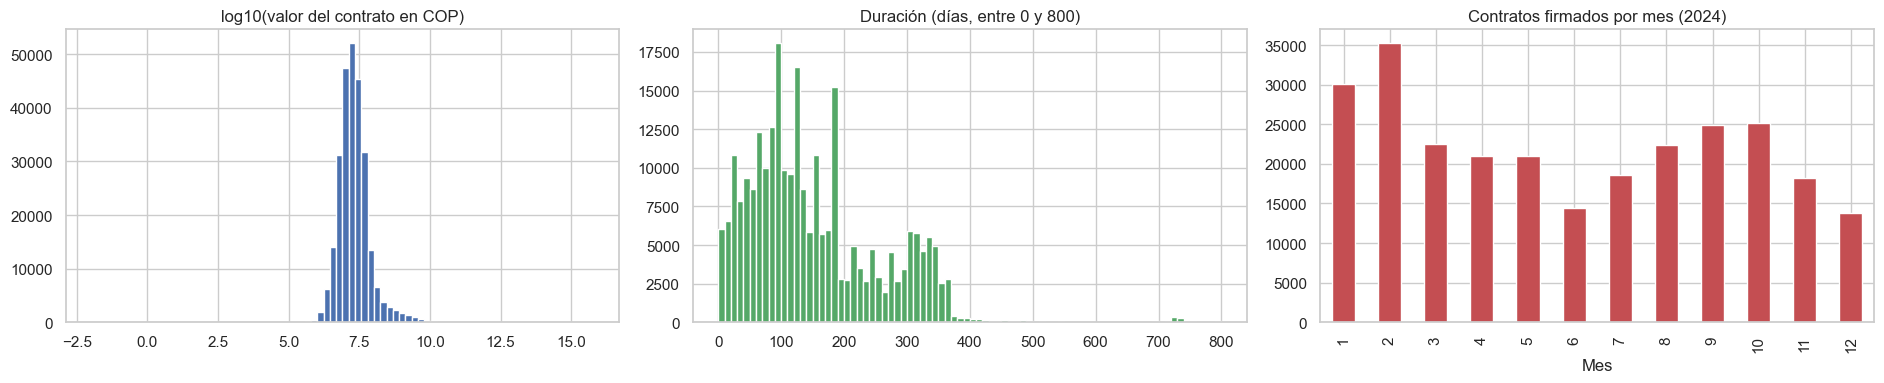

In [9]:
duracion_eda = (df['fecha_de_fin_del_contrato'] - df['fecha_de_inicio_del_contrato']).dt.days
fig, axes = plt.subplots(1, 3, figsize=(19, 4))
np.log10(df.loc[df['valor_del_contrato'] > 0, 'valor_del_contrato']).plot.hist(bins=80, ax=axes[0], color='#4C72B0')
axes[0].set(title='log10(valor del contrato en COP)', ylabel='')
duracion_eda[duracion_eda.between(0, 800)].plot.hist(bins=80, ax=axes[1], color='#55A868')
axes[1].set(title='Duración (días, entre 0 y 800)', ylabel='')
df['fecha_de_firma'].dt.month.value_counts().sort_index().plot.bar(ax=axes[2], color='#C44E52')
axes[2].set(title='Contratos firmados por mes (2024)', xlabel='Mes', ylabel='')
plt.tight_layout()
plt.show()

- En escala logarítmica, el valor se concentra entre 10⁶ y 10⁸ COP (de 1 a 100 millones), con colas largas hacia ambos lados.
- La duración tiene picos en meses "redondos" (unos 30, 90, 180 y 330 días), típicos de los contratos de prestación de servicios.
- Enero y febrero concentran más firmas, porque las entidades contratan a su personal de apoyo al inicio de la vigencia fiscal.

### 3.7 Cuantificación de registros inválidos

In [10]:
invalidos = {
    'Valor del contrato <= 0': (df['valor_del_contrato'] <= 0).sum(),
    'Valor < 100.000 COP (posible error de digitación)': (df['valor_del_contrato'].between(0, 1e5, inclusive='neither')).sum(),
    'Valor > 1 billón COP (outlier imposible)': (df['valor_del_contrato'] > 1e12).sum(),
    'Fecha de fin anterior a la de inicio': (duracion_eda < 0).sum(),
    'Duración mayor a 10 años': (duracion_eda > 3650).sum(),
    'Valor pagado mayor al valor del contrato': (df['valor_pagado'] > df['valor_del_contrato']).sum(),
    'Valor pendiente de pago negativo': (df['valor_pendiente_de_pago'] < 0).sum(),
}
pd.Series(invalidos, name='registros').to_frame().assign(porcentaje=lambda t: (t['registros'] / len(df) * 100).round(3))

,registros,porcentaje
Valor del contrato <= 0,1962,0.734
Valor < 100.000 COP (posible error de digitación),136,0.051
Valor > 1 billón COP (outlier imposible),2,0.001
Fecha de fin anterior a la de inicio,2,0.001
Duración mayor a 10 años,40,0.015
Valor pagado mayor al valor del contrato,201,0.075
Valor pendiente de pago negativo,201,0.075


## 4. Preparación de los datos
### 4.1 Tratamiento de valores nulos
| Columna | Tratamiento | Justificación |
|---|---|---|
| `fecha_de_inicio_del_contrato` | Imputar con `fecha_de_firma` | Si no se reporta el inicio, el supuesto más razonable es que el contrato empezó al firmarse. En el resto de los datos, inicio y firma casi siempre coinciden en la misma semana (mediana de 1 día) |
| `fecha_de_fin_del_contrato` | Eliminar el registro (solo 2 casos) | Sin fecha de fin no se puede calcular la duración, que es una variable del modelo, y no hay una regla confiable para imputarla. Con tan pocos casos, eliminarlos no sesga el análisis |
| Categóricas con `No Definido` / vacío | Convertir a la categoría explícita **`Sin información`** | Eliminar filas perdería contratos válidos. Imputar con la moda inventaría información. Una categoría explícita conserva el dato y deja visible que falta |
| Columnas de valor (`valor_*`, `dias_adicionados`) | Sin nulos tras la conversión. Si apareciera alguno, se imputa con 0 (sin pagos ni prórrogas reportados) | En SECOP II un campo de ejecución vacío significa que no hay reporte |

In [11]:
# Diferencia entre firma e inicio cuando ambas existen (para respaldar la imputación)
dif_dias = (df['fecha_de_inicio_del_contrato'] - df['fecha_de_firma']).dt.days
print('Días entre firma e inicio (contratos con ambas fechas):')
print(dif_dias.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1).to_string())

n_nulos_inicio = df['fecha_de_inicio_del_contrato'].isna().sum()
df['fecha_de_inicio_del_contrato'] = df['fecha_de_inicio_del_contrato'].fillna(df['fecha_de_firma'])
print(f'\nfecha_de_inicio_del_contrato: {n_nulos_inicio:,} nulos imputados con fecha_de_firma')

n_sin_fin = df['fecha_de_fin_del_contrato'].isna().sum()
df = df.dropna(subset=['fecha_de_fin_del_contrato'])
print(f'fecha_de_fin_del_contrato: {n_sin_fin:,} registros sin fecha de fin eliminados')

for col in COLS_VALOR:
    df[col] = df[col].fillna(0)

for col in COLS_CATEGORICAS:
    df[col] = (df[col].fillna('Sin información').str.strip()
               .replace({'No Definido': 'Sin información', 'No definido': 'Sin información'}))

print('Nulos restantes:', int(df.isna().sum().sum()))

Días entre firma e inicio (contratos con ambas fechas):
count   265,061.000
mean          2.600
std          22.000
min      -2,178.000
25%           0.000
50%           1.000
75%           3.000
90%           6.000
max       1,461.000

fecha_de_inicio_del_contrato: 2,097 nulos imputados con fecha_de_firma
fecha_de_fin_del_contrato: 2 registros sin fecha de fin eliminados


Nulos restantes: 0


### 4.2 Tratamiento de duplicados
En la exploración no aparecieron duplicados exactos ni de `id_contrato`. El paso se deja de todos modos en el flujo, porque el endpoint se actualiza a diario y en otra descarga podrían aparecer. Se usa `id_contrato` como clave, porque es el identificador único del contrato.

In [12]:
antes = len(df)
df = df.drop_duplicates(subset='id_contrato', keep='first')
print(f'Duplicados eliminados: {antes - len(df):,} | Registros: {len(df):,}')

Duplicados eliminados: 0 | Registros: 267,156


### 4.3 Ingeniería de variables
- `duracion_dias`: días entre la fecha de inicio y la de fin.
- `valor_mensual`: `valor_del_contrato / (duracion_dias / 30,4)`. Es el "tamaño" del contrato por mes; para la prestación de servicios equivale a los honorarios mensuales.
- `pct_pagado`: `valor_pagado / valor_del_contrato`, recortado al intervalo [0, 1]. Mide la ejecución financiera reportada.
- `prorrogado`: 1 si `dias_adicionados > 0`.

In [13]:
df['duracion_dias'] = (df['fecha_de_fin_del_contrato'] - df['fecha_de_inicio_del_contrato']).dt.days

### 4.4 Eliminación de registros inválidos
Se aplican filtros de plausibilidad, en orden, registrando cuántas filas elimina cada uno. Los umbrales son amplios a propósito: solo se quitan valores **imposibles o claramente erróneos**, no los contratos grandes legítimos.

In [14]:
filtros = [
    ('Valor entre 100.000 COP y 1 billón COP', lambda d: d['valor_del_contrato'].between(1e5, 1e12)),
    ('Duración entre 1 día y 10 años',          lambda d: d['duracion_dias'].between(1, 3650)),
    ('Días adicionados entre 0 y 10 años',      lambda d: d['dias_adicionados'].between(0, 3650)),
]
bitacora = []
for nombre, condicion in filtros:
    antes = len(df)
    df = df[condicion(df)]
    bitacora.append({'filtro': nombre, 'eliminados': antes - len(df), 'restantes': len(df)})
df = df.reset_index(drop=True)
display(pd.DataFrame(bitacora))
print(f'Registros finales: {len(df):,} ({len(df) / len(df_raw):.1%} de la muestra descargada)')

,filtro,eliminados,restantes
0,Valor entre 100.000 COP y 1 billón COP,2100,265056
1,Duración entre 1 día y 10 años,1220,263836
2,Días adicionados entre 0 y 10 años,0,263836


Registros finales: 263,836 (98.8% de la muestra descargada)


In [15]:
df['valor_mensual'] = df['valor_del_contrato'] / (df['duracion_dias'] / 30.4)
df['pct_pagado'] = (df['valor_pagado'] / df['valor_del_contrato']).clip(0, 1)
df['prorrogado'] = (df['dias_adicionados'] > 0).astype(int)
print(f"Contratos con pago registrado mayor al valor (recortados a 100 %): {(df['valor_pagado'] > df['valor_del_contrato']).sum():,}")
df[['valor_del_contrato', 'duracion_dias', 'valor_mensual', 'pct_pagado', 'dias_adicionados']].describe().T

Contratos con pago registrado mayor al valor (recortados a 100 %): 201


,count,mean,std,min,25%,50%,75%,max
valor_del_contrato,"263,836.000","140,042,782.529","2,854,788,630.996","100,000.000","9,274,856.000","18,000,000.000","37,482,931.750","712,569,236,855.000"
duracion_dias,"263,836.000",154.564,119.985,1.000,74.000,121.000,213.000,"3,650.000"
valor_mensual,"263,836.000","36,033,094.850","2,129,703,460.161","4,695.442","2,827,953.659","4,321,322.314","7,021,887.979","868,486,735,860.800"
pct_pagado,"263,836.000",0.563,0.472,0.000,0.000,0.892,1.000,1.000
dias_adicionados,"263,836.000",6.048,23.885,0.000,0.000,0.000,0.000,"1,825.000"


### 4.5 Tratamiento de variables categóricas
1. **Normalización de texto**: se unifican mayúsculas en `estado_contrato` (por ejemplo, `terminado` pasa a `Terminado`).
2. **Agrupación de categorías poco frecuentes**: las 15 modalidades se reducen a 5 grupos con sentido jurídico.
3. **Recodificación**: `tipodocproveedor` se convierte en `tipo_contratista` (persona natural o jurídica).
4. **Derivación desde un código**: del código UNSPSC se extrae el **segmento** (los 2 primeros dígitos) y se le pone nombre.
5. **One-hot encoding** (`pd.get_dummies`) para calcular la proporción de cada categoría por cluster.

**¿Por qué las categóricas no entran a K-Means?** K-Means calcula distancias euclidianas a un centroide (una media). Con variables one-hot esa media no tiene un significado claro, y decenas de columnas binarias dominarían la distancia frente a las 4 variables numéricas. Para mezclar ambos tipos haría falta otro algoritmo, como K-Prototypes. Aquí las categóricas se usan como **validación externa**: si los grupos, formados solo con variables numéricas, también se diferencian por modalidad o tipo de contratista, es evidencia de que el patrón es real.

In [16]:
df['estado_contrato'] = df['estado_contrato'].str.capitalize()


def agrupar_modalidad(modalidad):
    m = modalidad.lower()
    if 'directa' in m:
        return 'Contratación directa'
    if 'especial' in m:
        return 'Régimen especial'
    if 'mínima' in m or 'minima' in m:
        return 'Mínima cuantía'
    if 'enajenación' in m or 'enajenacion' in m:
        return 'Otra'
    return 'Competitiva (licitación/selección/concurso)'


df['modalidad_grupo'] = df['modalidad_de_contratacion'].map(agrupar_modalidad)
df['tipo_contratista'] = np.select(
    [df['tipodocproveedor'].eq('NIT'),
     df['tipodocproveedor'].str.contains('Cédula|Pasaporte|Permiso|Tarjeta|Registro', regex=True)],
    ['Persona jurídica', 'Persona natural'], default='Sin información')

SEGMENTOS_UNSPSC = {
    '80': 'Gestión y servicios profesionales', '85': 'Salud', '93': 'Servicios cívicos y políticos',
    '81': 'Ingeniería, investigación y tecnología', '86': 'Educación y formación',
    '72': 'Construcción y mantenimiento', '84': 'Financieros y seguros', '78': 'Transporte y almacenaje',
    '90': 'Viajes, alimentación y eventos', '77': 'Medio ambiente', '82': 'Editoriales y diseño',
    '43': 'TIC y telecomunicaciones',
}
segmento = df['codigo_de_categoria_principal'].str.replace('V1.', '', regex=False).str[:2]
df['segmento_unspsc'] = segmento.map(SEGMENTOS_UNSPSC).fillna('Otros segmentos')
df['mes_firma'] = df['fecha_de_firma'].dt.month

for col in ['modalidad_grupo', 'tipo_contratista', 'segmento_unspsc']:
    print(f'--- {col} ---')
    print((df[col].value_counts(normalize=True) * 100).round(2).to_string(), '\n')

dummies = pd.get_dummies(df[['modalidad_grupo', 'tipo_contratista', 'estado_contrato', 'orden']],
                         prefix=['mod', 'contratista', 'estado', 'orden'], dtype=int)
print('Columnas one-hot creadas para la caracterización:', dummies.shape[1])

--- modalidad_grupo ---
modalidad_grupo
Contratación directa                          76.460
Régimen especial                              16.250
Mínima cuantía                                 5.070
Competitiva (licitación/selección/concurso)    2.220
Otra                                           0.010 

--- tipo_contratista ---
tipo_contratista
Persona natural    85.260
Persona jurídica   14.450
Sin información     0.290 

--- segmento_unspsc ---
segmento_unspsc
Gestión y servicios profesionales        71.340
Otros segmentos                           7.540
Salud                                     6.580
Servicios cívicos y políticos             4.750
Ingeniería, investigación y tecnología    2.400
Educación y formación                     1.850
Construcción y mantenimiento              1.440
Financieros y seguros                     0.840
Transporte y almacenaje                   0.740
Viajes, alimentación y eventos            0.720
Medio ambiente                            0.670
Edi

Columnas one-hot creadas para la caracterización: 18


## 5. Selección de variables y estandarización
### 5.1 Variables del modelo
| Variable del modelo | Construcción | Qué captura |
|---|---|---|
| `log_valor_mensual` | `log10(valor_mensual)` | Tamaño económico del contrato por mes |
| `log_duracion` | `log(1 + duracion_dias)` | Plazo del contrato |
| `pct_pagado` | `valor_pagado / valor` (0 a 1) | Ejecución financiera reportada |
| `log_dias_adicionados` | `log(1 + dias_adicionados)` | Intensidad de las prórrogas |

**Criterios de selección:**
- **Se evita la redundancia.** El valor total cumple `log(valor) ≈ log(valor_mensual) + log(duración) + constante`, así que con dos de las tres variables queda determinada la tercera. Se eligen *valor mensual* y *duración* porque están menos correlacionadas entre sí que *valor total* y *duración*. Por la misma razón se descarta `valor_facturado`, que tiene una correlación de 0,9 con `valor_pagado`.
- **Se corrige la asimetría.** Los logaritmos reducen el efecto de los valores extremos, que en K-Means "arrastran" los centroides.
- **Las variables son numéricas y continuas**, como requiere la distancia euclidiana.

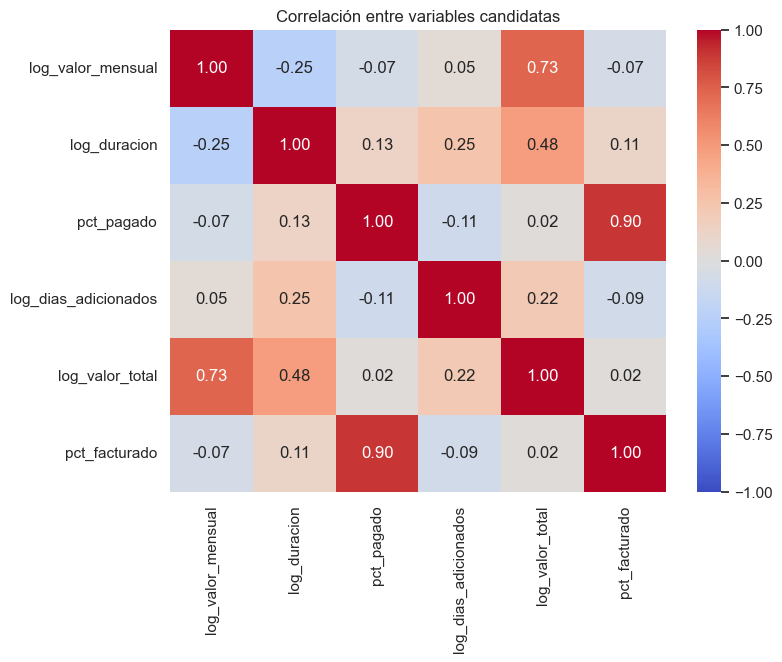

In [17]:
df['log_valor_mensual'] = np.log10(df['valor_mensual'])
df['log_duracion'] = np.log1p(df['duracion_dias'])
df['log_dias_adicionados'] = np.log1p(df['dias_adicionados'])
df['log_valor_total'] = np.log10(df['valor_del_contrato'])
df['pct_facturado'] = (df['valor_facturado'] / df['valor_del_contrato']).clip(0, 1)

VARIABLES_MODELO = ['log_valor_mensual', 'log_duracion', 'pct_pagado', 'log_dias_adicionados']

plt.figure(figsize=(8, 6))
sns.heatmap(df[VARIABLES_MODELO + ['log_valor_total', 'pct_facturado']].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación entre variables candidatas')
plt.show()

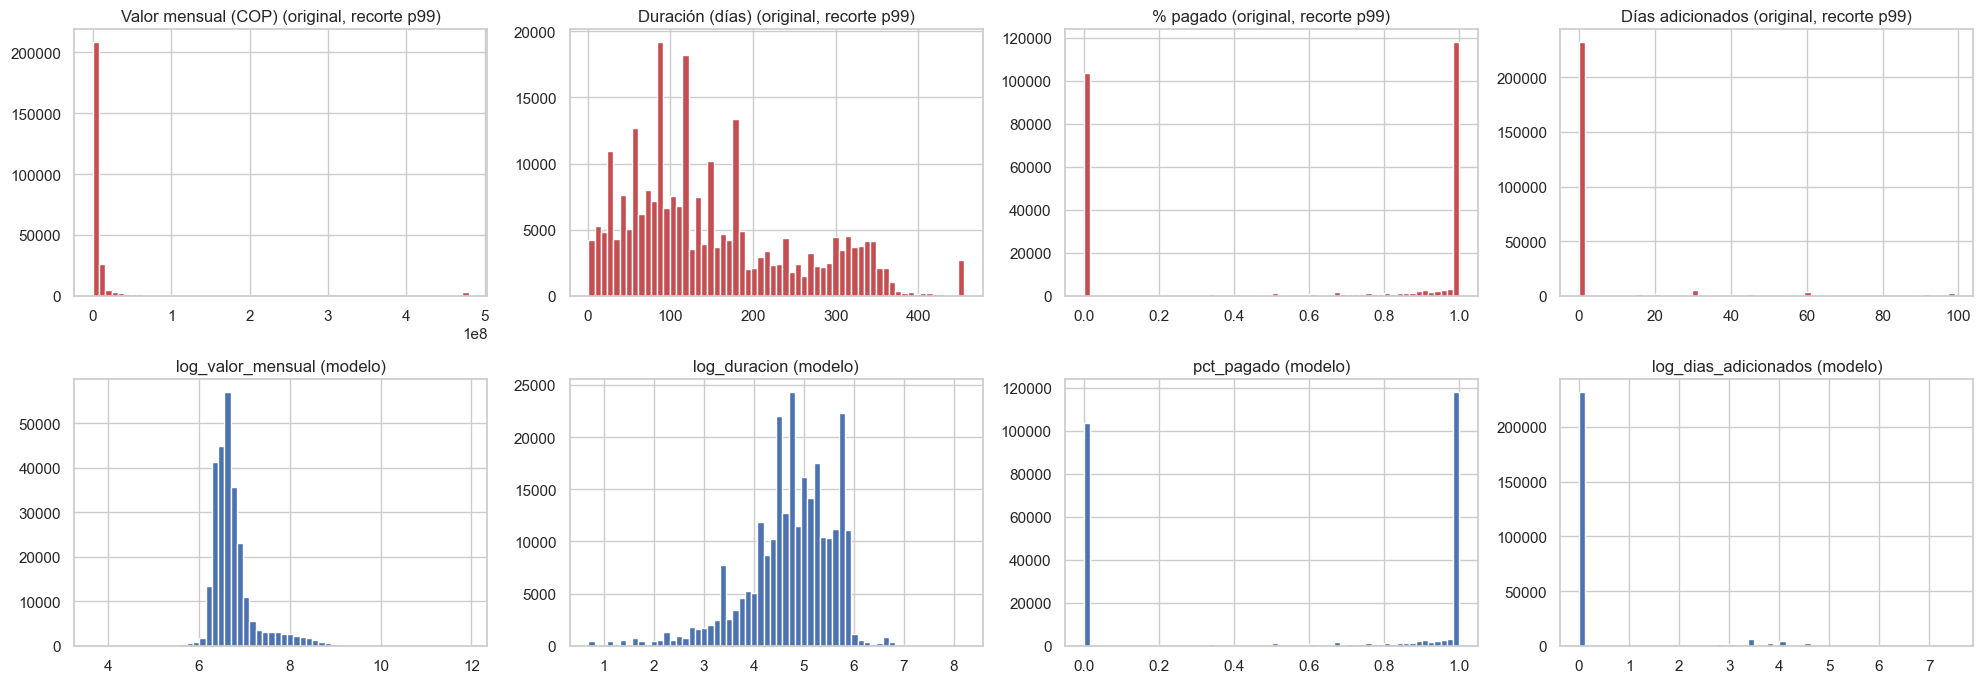

Contratos con pct_pagado = 0: 39.2% | con pct_pagado = 1: 40.7%
Contratos prorrogados: 12.2%


In [18]:
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
originales = [('valor_mensual', 'Valor mensual (COP)'), ('duracion_dias', 'Duración (días)'),
              ('pct_pagado', '% pagado'), ('dias_adicionados', 'Días adicionados')]
for i, ((original, titulo), transformada) in enumerate(zip(originales, VARIABLES_MODELO)):
    df[original].clip(upper=df[original].quantile(0.99)).plot.hist(bins=60, ax=axes[0, i], color='#C44E52')
    axes[0, i].set_title(f'{titulo} (original, recorte p99)')
    df[transformada].plot.hist(bins=60, ax=axes[1, i], color='#4C72B0')
    axes[1, i].set_title(f'{transformada} (modelo)')
for ax in axes.ravel():
    ax.set_ylabel('')
plt.tight_layout()
plt.show()
print(f"Contratos con pct_pagado = 0: {(df['pct_pagado'] == 0).mean():.1%} | con pct_pagado = 1: {(df['pct_pagado'] == 1).mean():.1%}")
print(f"Contratos prorrogados: {df['prorrogado'].mean():.1%}")

### 5.2 Estandarización
Las cuatro variables tienen rangos muy distintos: `pct_pagado` va de 0 a 1 y `log_valor_mensual` de 4 a 12. K-Means usa distancia euclidiana, así que sin estandarizar dominaría la variable de mayor rango. Se aplica `StandardScaler` para que cada variable quede con media 0 y desviación estándar 1 y aporte por igual.

In [19]:
escalador = StandardScaler()
X = escalador.fit_transform(df[VARIABLES_MODELO])
print(f'Matriz de entrenamiento: {X.shape[0]:,} registros x {X.shape[1]} variables')
pd.DataFrame(X, columns=VARIABLES_MODELO).describe().loc[['mean', 'std', 'min', 'max']].round(3)

Matriz de entrenamiento: 263,836 registros x 4 variables


,log_valor_mensual,log_duracion,pct_pagado,log_dias_adicionados
mean,0.000,-0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000
min,-6.064,-4.606,-1.193,-0.359
max,10.244,3.939,0.925,5.863


## 6. Selección y justificación del algoritmo
| Algoritmo | Ventajas | Desventajas en este caso |
|---|---|---|
| **K-Means** | Simple, interpretable (centroides), escala bien | Recorre todos los datos en cada iteración |
| **MiniBatch K-Means** | Mismo objetivo que K-Means, pero actualiza los centroides con lotes aleatorios: varias veces más rápido y con menos memoria | Solución aproximada (inercia un poco mayor) |
| **DBSCAN** | Encuentra formas arbitrarias y detecta ruido | Muy sensible a `eps`. Con densidades tan desiguales como aquí, forma un único grupo gigante o marca casi todo como ruido. Además, su costo de vecindad crece mucho con 260.000 puntos |
| **Gaussian Mixture** | Clusters elípticos y asignación probabilística | Supone normalidad. `pct_pagado` y `log_dias_adicionados` tienen masas en 0 y 1 que no son gaussianas. Es más lento |

**Algoritmo seleccionado: MiniBatch K-Means.**
1. **Escala**: entrena con todos los registros en segundos. Si SEIA lo aplicara sobre los 5,7 millones de contratos del endpoint, seguiría siendo viable.
2. **Interpretabilidad**: cada cluster queda resumido en un centroide, que se traduce a un contrato típico (COP por mes, días de duración, % pagado, días de prórroga).
3. **Encaje con los datos**: las 4 variables son numéricas, estandarizadas y con la asimetría corregida.
4. **Evidencia empírica**: en la comparación siguiente, sobre una muestra de 100.000 contratos, MiniBatch K-Means logra las mismas métricas que K-Means en menos tiempo. Gaussian Mixture y DBSCAN quedan claramente peor.

In [20]:
rng = np.random.RandomState(SEED)
X_muestra = X[rng.choice(len(X), 100_000, replace=False)]

candidatos = {
    'MiniBatch K-Means (k=4)': MiniBatchKMeans(n_clusters=4, batch_size=4096, n_init=10, random_state=SEED),
    'K-Means (k=4)': KMeans(n_clusters=4, n_init=10, random_state=SEED),
    'Gaussian Mixture (4 comp.)': GaussianMixture(n_components=4, covariance_type='full', random_state=SEED),
}
comparacion = []
for nombre, modelo_c in candidatos.items():
    inicio = time.time()
    etq = modelo_c.fit_predict(X_muestra)
    comparacion.append({'algoritmo': nombre, 'tiempo_s': time.time() - inicio,
                        'silhouette': silhouette_score(X_muestra, etq, sample_size=20_000, random_state=SEED),
                        'davies_bouldin': davies_bouldin_score(X_muestra, etq),
                        'calinski_harabasz': calinski_harabasz_score(X_muestra, etq)})
pd.DataFrame(comparacion).set_index('algoritmo').round(3)

,tiempo_s,silhouette,davies_bouldin,calinski_harabasz
algoritmo,,,,
MiniBatch K-Means (k=4),0.322,0.451,0.894,"55,435.696"
K-Means (k=4),0.148,0.450,0.898,"55,449.472"
Gaussian Mixture (4 comp.),0.370,0.249,2.131,"29,943.304"


In [21]:
# DBSCAN sobre una submuestra de 20.000 puntos (con más puntos el costo crece demasiado)
X_db = X_muestra[:20_000]
filas = []
for eps in [0.2, 0.3, 0.5, 0.8]:
    etq_db = DBSCAN(eps=eps, min_samples=20).fit_predict(X_db)
    n_clusters = len(set(etq_db)) - (1 if -1 in etq_db else 0)
    tamanos_db = pd.Series(etq_db[etq_db >= 0]).value_counts(normalize=True)
    filas.append({'eps': eps, 'clusters': n_clusters, '% ruido': (etq_db == -1).mean() * 100,
                  '% en el cluster más grande': tamanos_db.max() * 100 if len(tamanos_db) else 0})
pd.DataFrame(filas).round(2)

,eps,clusters,% ruido,% en el cluster más grande
0,0.200,12,24.700,58.970
1,0.300,12,12.590,91.310
2,0.500,4,4.100,89.700
3,0.800,1,1.230,100.000


### Resultado de la comparación
- **MiniBatch K-Means y K-Means obtienen prácticamente las mismas métricas**: Silhouette ≈ 0,45, Davies-Bouldin ≈ 0,89 y Calinski-Harabasz ≈ 55.400. La aproximación por mini-lotes no pierde calidad y es más rápida. La ventaja de tiempo crece con el tamaño de los datos: K-Means recorre todos los registros en cada iteración, mientras que MiniBatch K-Means usa lotes de 4.096.
- **Gaussian Mixture queda claramente peor**: Silhouette ≈ 0,25 y Davies-Bouldin ≈ 2,1. Sus componentes gaussianas se ajustan a las "masas" de valores repetidos (`pct_pagado` igual a 0 o 1, `dias_adicionados` igual a 0) en lugar de separar perfiles de contrato, y el resultado son grupos muy solapados.
- **DBSCAN no encuentra un `eps` útil**. Con `eps = 0,2` fragmenta los datos en una docena de grupos y deja cerca del 25 % como ruido. Con `eps = 0,5`, un solo grupo concentra cerca del 90 % de los puntos. Con `eps = 0,8`, todo queda en un único cluster. Los datos forman una nube continua con zonas de densidad distinta, no "islas" separadas, que es lo que DBSCAN necesita.

**Conclusión:** MiniBatch K-Means ofrece la mejor relación entre calidad, interpretabilidad y escalabilidad.

## 7. Determinación del número de clusters (k)
Se entrena MiniBatch K-Means para `k = 2, …, 10` sobre todos los registros, con la misma configuración del modelo final (`n_init = 10`), y se combinan cuatro criterios:
- **Método del codo**: la inercia (suma de distancias al cuadrado a cada centroide). Se busca el punto donde agregar clusters deja de reducirla de forma importante.
- **Silhouette Score** (mayor es mejor). Su costo es O(n²), así que se estima con una muestra aleatoria de 20.000 puntos, que es la práctica habitual.
- **Davies-Bouldin Index** (menor es mejor), con todos los datos.
- **Calinski-Harabasz Score** (mayor es mejor), con todos los datos.

In [22]:
resultados_k = []
for k in range(2, 11):
    inicio = time.time()
    modelo_k = MiniBatchKMeans(n_clusters=k, batch_size=4096, n_init=10, random_state=SEED).fit(X)
    etq_k = modelo_k.labels_
    resultados_k.append({
        'k': k,
        'inercia': modelo_k.inertia_,
        'silhouette': silhouette_score(X, etq_k, sample_size=20_000, random_state=SEED),
        'davies_bouldin': davies_bouldin_score(X, etq_k),
        'calinski_harabasz': calinski_harabasz_score(X, etq_k),
        'tiempo_s': round(time.time() - inicio, 1),
    })
resultados_k = pd.DataFrame(resultados_k).set_index('k')
resultados_k['reduccion_inercia_%'] = -resultados_k['inercia'].pct_change() * 100
resultados_k.round(3)

,inercia,silhouette,davies_bouldin,calinski_harabasz,tiempo_s,reduccion_inercia_%
k,,,,,,
2,"793,370.725",0.346,1.423,"87,156.150",2.000,NaN
3,"556,481.949",0.414,1.071,"118,312.317",1.700,29.859
4,"402,905.347",0.443,0.936,"144,107.351",1.700,27.598
5,"357,690.595",0.452,1.031,"129,651.898",1.800,11.222
6,"311,515.387",0.424,0.991,"126,068.606",1.700,12.909
7,"281,085.190",0.353,1.040,"121,546.191",1.600,9.768
8,"270,576.183",0.413,1.082,"109,556.817",1.700,3.739
9,"226,948.456",0.359,1.093,"120,741.462",1.500,16.124
10,"216,009.485",0.314,1.147,"114,246.868",1.300,4.820


,mejor k
Silhouette (máx.),5
Davies-Bouldin (mín.),4
Calinski-Harabasz (máx.),4


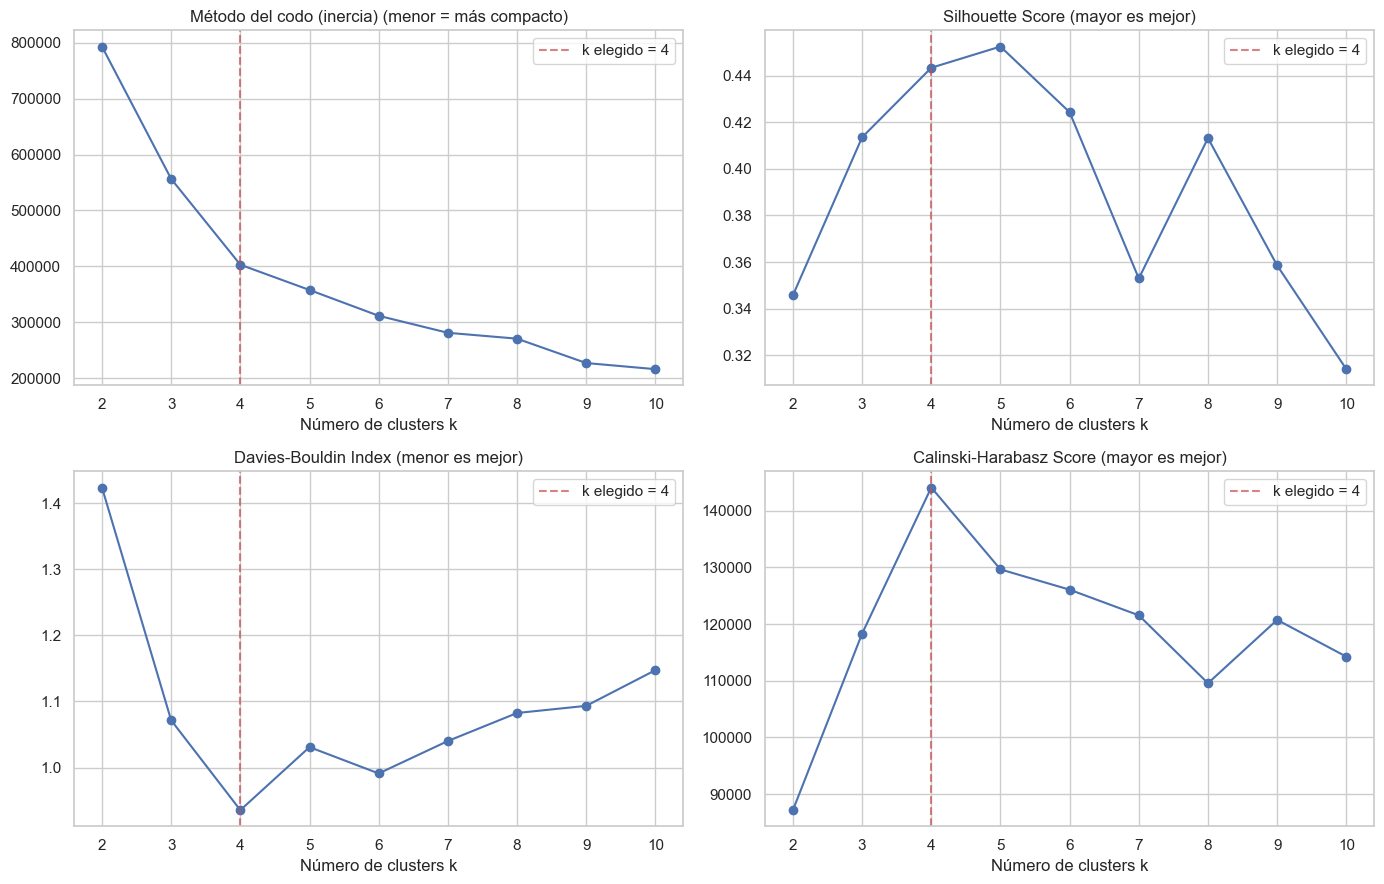

In [23]:
mejor = pd.Series({
    'Silhouette (máx.)': resultados_k['silhouette'].idxmax(),
    'Davies-Bouldin (mín.)': resultados_k['davies_bouldin'].idxmin(),
    'Calinski-Harabasz (máx.)': resultados_k['calinski_harabasz'].idxmax(),
}, name='mejor k')
display(mejor.to_frame())

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
graficos = [('inercia', 'Método del codo (inercia)', 'menor = más compacto'),
            ('silhouette', 'Silhouette Score', 'mayor es mejor'),
            ('davies_bouldin', 'Davies-Bouldin Index', 'menor es mejor'),
            ('calinski_harabasz', 'Calinski-Harabasz Score', 'mayor es mejor')]
for ax, (col, titulo, nota) in zip(axes.ravel(), graficos):
    ax.plot(resultados_k.index, resultados_k[col], marker='o', color='#4C72B0')
    ax.axvline(4, color='#C44E52', linestyle='--', alpha=0.7, label='k elegido = 4')
    ax.set(title=f'{titulo} ({nota})', xlabel='Número de clusters k', xticks=resultados_k.index)
    ax.legend()
plt.tight_layout()
plt.show()

### Decisión: k = 4

| Criterio | Mejor k | Lectura |
|---|---|---|
| Método del codo | **4** | La inercia baja ≈ 30 % de k = 2 a 3 y ≈ 28 % de 3 a 4, pero solo ≈ 11 % de 4 a 5. A partir de k = 4, cada cluster adicional aporta poco |
| Davies-Bouldin | **4** | Mínimo global (≈ 0,94) |
| Calinski-Harabasz | **4** | Máximo global (≈ 144.000) |
| Silhouette | 5 | Máximo en k = 5 (≈ 0,45), con k = 4 (≈ 0,44) prácticamente empatado: la diferencia es menor a 0,01 |

**Tres de los cuatro criterios eligen k = 4**, y el cuarto lo deja prácticamente empatado con su máximo. También pesa la utilidad: con k = 4 cada grupo tiene un tamaño relevante (entre el 10 % y el 49 % de los contratos) y una interpretación de negocio clara. En las pruebas con k = 5, el grupo de alto valor mensual se parte en dos subgrupos pequeños; eso agrega detalle, pero empeora Davies-Bouldin y Calinski-Harabasz.

## 8. Entrenamiento del modelo final
Se entrena MiniBatch K-Means con `k = 4` sobre todos los contratos, con `n_init = 10`: se prueban 10 inicializaciones k-means++ y se conserva la de menor inercia.

**Nombres estables.** K-Means numera los clusters al azar. Para que la interpretación no dependa de esa numeración, cada cluster se nombra con **reglas sobre su centroide**, en unidades reales:
1. El centroide con más días adicionados es **"Prorrogados"**.
2. De los restantes, el de mayor valor mensual es **"Cortos de alto valor mensual"**.
3. De los dos últimos, el de mayor % pagado es **"Ejecutados y pagados"**, y el otro es **"Sin pagos registrados"**.

In [24]:
K_OPTIMO = 4
inicio = time.time()
modelo = MiniBatchKMeans(n_clusters=K_OPTIMO, batch_size=4096, n_init=10, max_iter=300, random_state=SEED).fit(X)
print(f'Entrenamiento: {time.time() - inicio:.2f} s | Mini-lotes procesados: {modelo.n_steps_} | Inercia: {modelo.inertia_:,.0f}')

centroides_reales = pd.DataFrame(escalador.inverse_transform(modelo.cluster_centers_), columns=VARIABLES_MODELO)
centroides_reales['valor_mensual_cop'] = 10 ** centroides_reales['log_valor_mensual']
centroides_reales['duracion_dias'] = np.expm1(centroides_reales['log_duracion'])
centroides_reales['dias_adicionados'] = np.expm1(centroides_reales['log_dias_adicionados'])


def nombrar_clusters(cent):
    restantes = list(cent.index)
    prorrogado = cent.loc[restantes, 'dias_adicionados'].idxmax(); restantes.remove(prorrogado)
    alto_valor = cent.loc[restantes, 'valor_mensual_cop'].idxmax(); restantes.remove(alto_valor)
    pagado = cent.loc[restantes, 'pct_pagado'].idxmax(); restantes.remove(pagado)
    sin_pago = restantes[0]
    return {pagado: 'Ejecutados y pagados', sin_pago: 'Sin pagos registrados',
            prorrogado: 'Prorrogados', alto_valor: 'Cortos de alto valor mensual'}


ORDEN_NOMBRES = ['Ejecutados y pagados', 'Sin pagos registrados', 'Prorrogados', 'Cortos de alto valor mensual']
nombres = nombrar_clusters(centroides_reales)
nuevo_id = {viejo: ORDEN_NOMBRES.index(nombre) for viejo, nombre in nombres.items()}

df['cluster'] = pd.Series(modelo.labels_).map(nuevo_id).values
NOMBRE_CLUSTER = {i: f'C{i} · {n}' for i, n in enumerate(ORDEN_NOMBRES)}
df['cluster_nombre'] = df['cluster'].map(NOMBRE_CLUSTER)
orden_centroides = [viejo for viejo, _ in sorted(nuevo_id.items(), key=lambda par: par[1])]
centroides_std = modelo.cluster_centers_[orden_centroides]
centroides_reales = centroides_reales.loc[orden_centroides].reset_index(drop=True)
centroides_reales.index = [NOMBRE_CLUSTER[i] for i in range(K_OPTIMO)]

tamanos = df['cluster_nombre'].value_counts().reindex(NOMBRE_CLUSTER.values())
display(pd.DataFrame({'contratos': tamanos, 'porcentaje': tamanos / len(df) * 100}).round(2))
print('Centroides en unidades reales:')
centroides_reales[['valor_mensual_cop', 'duracion_dias', 'pct_pagado', 'dias_adicionados']].round(2)

Entrenamiento: 0.03 s | Mini-lotes procesados: 12 | Inercia: 402,905


,contratos,porcentaje
cluster_nombre,,
C0 · Ejecutados y pagados,128599,48.740
C1 · Sin pagos registrados,79541,30.150
C2 · Prorrogados,29599,11.220
C3 · Cortos de alto valor mensual,26097,9.890


Centroides en unidades reales:


,valor_mensual_cop,duracion_dias,pct_pagado,dias_adicionados
C0 · Ejecutados y pagados,"4,197,524.390",136.130,0.960,0.010
C1 · Sin pagos registrados,"3,996,574.740",115.480,0.020,0.010
C2 · Prorrogados,"6,052,439.600",207.040,0.410,39.460
C3 · Cortos de alto valor mensual,"44,850,754.390",26.650,0.360,0.060


## 9. Evaluación del modelo
- **Silhouette Score**: para cada punto, `s = (b − a) / max(a, b)`, donde *a* es la distancia media a los puntos de su cluster y *b* la distancia media al cluster vecino más cercano. Va de −1 a 1. Cerca de 1 = bien asignado; cerca de 0 = en la frontera; negativo = probablemente mal asignado. Aquí se promedia sobre 5 muestras independientes de 20.000 puntos.
- **Davies-Bouldin Index**: promedio, para cada cluster, de la razón entre su dispersión interna y la separación con el cluster más parecido. Menor es mejor; 0 es el ideal.
- **Calinski-Harabasz Score**: razón entre la dispersión *entre* clusters y la dispersión *dentro* de ellos, ajustada por n y k. Mayor es mejor. No tiene un máximo fijo, así que sirve para **comparar** soluciones con los mismos datos.

In [25]:
etiquetas = df['cluster'].values
siluetas = [silhouette_score(X, etiquetas, sample_size=20_000, random_state=s) for s in range(5)]
metricas = pd.DataFrame({
    'métrica': ['Silhouette Score', 'Davies-Bouldin Index', 'Calinski-Harabasz Score'],
    'valor': [np.mean(siluetas), davies_bouldin_score(X, etiquetas), calinski_harabasz_score(X, etiquetas)],
    'criterio': ['mayor es mejor (rango −1 a 1)', 'menor es mejor (mín. 0)', 'mayor es mejor (sin máximo)'],
    'datos usados': ['5 muestras de 20.000', f'{len(X):,} (todos)', f'{len(X):,} (todos)'],
})
print(f'Silhouette por muestra: {np.round(siluetas, 4)} -> media {np.mean(siluetas):.4f} ± {np.std(siluetas):.4f}')
metricas.round(4)

Silhouette por muestra: [0.447  0.4457 0.4451 0.4458 0.4481] -> media 0.4463 ± 0.0011


,métrica,valor,criterio,datos usados
0,Silhouette Score,0.446,mayor es mejor (rango −1 a 1),5 muestras de 20.000
1,Davies-Bouldin Index,0.936,menor es mejor (mín. 0),"263,836 (todos)"
2,Calinski-Harabasz Score,"144,107.351",mayor es mejor (sin máximo),"263,836 (todos)"


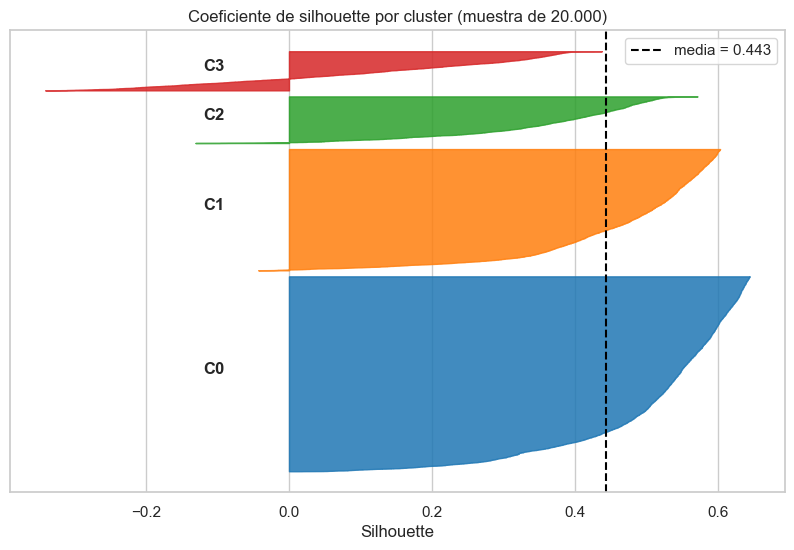

,media,mediana,pct_negativos
cluster,,,
C0 · Ejecutados y pagados,0.514,0.546,0.000
C1 · Sin pagos registrados,0.468,0.508,0.646
C2 · Prorrogados,0.357,0.392,1.810
C3 · Cortos de alto valor mensual,0.116,0.139,30.406


In [26]:
idx_s = np.random.RandomState(SEED).choice(len(X), 20_000, replace=False)
valores_s = silhouette_samples(X[idx_s], etiquetas[idx_s])
etq_s = etiquetas[idx_s]
colores = sns.color_palette('tab10', K_OPTIMO)

fig, ax = plt.subplots(figsize=(10, 6))
y_inf = 10
for c in range(K_OPTIMO):
    vals = np.sort(valores_s[etq_s == c])
    ax.fill_betweenx(np.arange(y_inf, y_inf + len(vals)), 0, vals, color=colores[c], alpha=0.85)
    ax.text(-0.12, y_inf + len(vals) / 2, f'C{c}', fontweight='bold')
    y_inf += len(vals) + 300
ax.axvline(valores_s.mean(), color='black', linestyle='--', label=f'media = {valores_s.mean():.3f}')
ax.set(title='Coeficiente de silhouette por cluster (muestra de 20.000)', xlabel='Silhouette', yticks=[])
ax.legend()
plt.show()

(pd.DataFrame({'cluster': [NOMBRE_CLUSTER[c] for c in etq_s], 'silhouette': valores_s})
   .groupby('cluster')['silhouette']
   .agg(media='mean', mediana='median', pct_negativos=lambda s: (s < 0).mean() * 100)
   .reindex(NOMBRE_CLUSTER.values()).round(3))

### Interpretación de las métricas del modelo final

| Métrica | Valor | Interpretación |
|---|---|---|
| **Silhouette** | ≈ 0,45 (± 0,001 entre muestras) | **Estructura razonable**. La guía habitual es: más de 0,5 = fuerte, de 0,25 a 0,5 = razonable, menos de 0,25 = débil. En promedio, cada contrato está claramente más cerca de su grupo que del grupo vecino, aunque hay fronteras compartidas, algo esperable en datos administrativos reales. La desviación mínima entre las 5 muestras confirma que estimar con muestras de 20.000 es fiable |
| **Davies-Bouldin** | ≈ 0,94 | Menor que 1: los clusters están, en promedio, **más separados entre sí que dispersos por dentro** |
| **Calinski-Harabasz** | ≈ 144.000 | Es el máximo entre todos los k evaluados: la dispersión entre grupos es muy superior a la dispersión dentro de ellos |

**Calidad por cluster (gráfico de silhouette):**
- **C0 "Ejecutados y pagados"** (≈ 0,51) y **C1 "Sin pagos registrados"** (≈ 0,47) son grupos compactos y bien separados, casi sin puntos negativos.
- **C2 "Prorrogados"** (≈ 0,36) tiene una calidad aceptable. Su frontera es la de los contratos con prórrogas cortas.
- **C3 "Cortos de alto valor mensual"** tiene un silhouette bajo (≈ 0,12) y cerca del 30 % de puntos con valor negativo. Es el grupo **más heterogéneo**: reúne compras, suministros, arrendamientos y servicios cortos de montos muy distintos, y en la dimensión de % pagado se mezcla con C0 y C1. Su interpretación es válida a nivel general, pero hay que leerla con más cautela que la de los otros tres.

## 10. Visualización de los grupos encontrados
### 10.1 Proyección PCA en 2 dimensiones

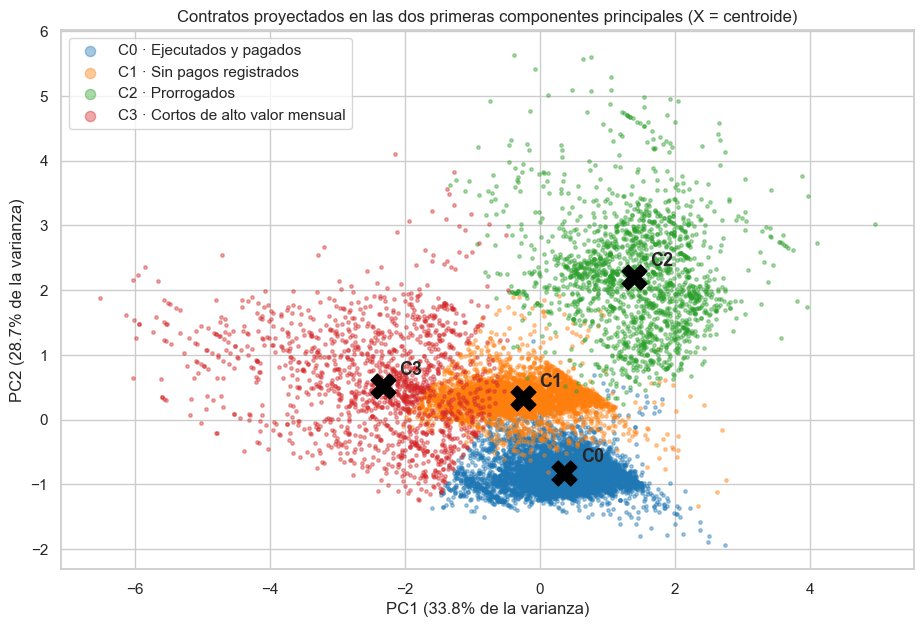

Varianza explicada por PC1 + PC2: 62.4%
Cargas de cada variable en las componentes:


,log_valor_mensual,log_duracion,pct_pagado,log_dias_adicionados
PC1,-0.518,0.726,0.253,0.374
PC2,0.354,0.097,-0.601,0.710


In [27]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
idx_v = np.random.RandomState(SEED).choice(len(X), 15_000, replace=False)
proy = pca.transform(X[idx_v])
proy_c = pca.transform(centroides_std)

fig, ax = plt.subplots(figsize=(11, 7))
for c in range(K_OPTIMO):
    m = etiquetas[idx_v] == c
    ax.scatter(proy[m, 0], proy[m, 1], s=6, alpha=0.4, color=colores[c], label=NOMBRE_CLUSTER[c])
ax.legend(markerscale=3, loc='upper left')
ax.scatter(proy_c[:, 0], proy_c[:, 1], marker='X', s=320, c='black')
for c in range(K_OPTIMO):
    ax.annotate(f'C{c}', proy_c[c], textcoords='offset points', xytext=(12, 8), fontsize=13, fontweight='bold')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} de la varianza)',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} de la varianza)',
       title='Contratos proyectados en las dos primeras componentes principales (X = centroide)')
plt.show()
print(f'Varianza explicada por PC1 + PC2: {pca.explained_variance_ratio_.sum():.1%}')
print('Cargas de cada variable en las componentes:')
pd.DataFrame(pca.components_, columns=VARIABLES_MODELO, index=['PC1', 'PC2']).round(3)

### 10.2 Valor mensual vs. duración, y % pagado vs. días adicionados

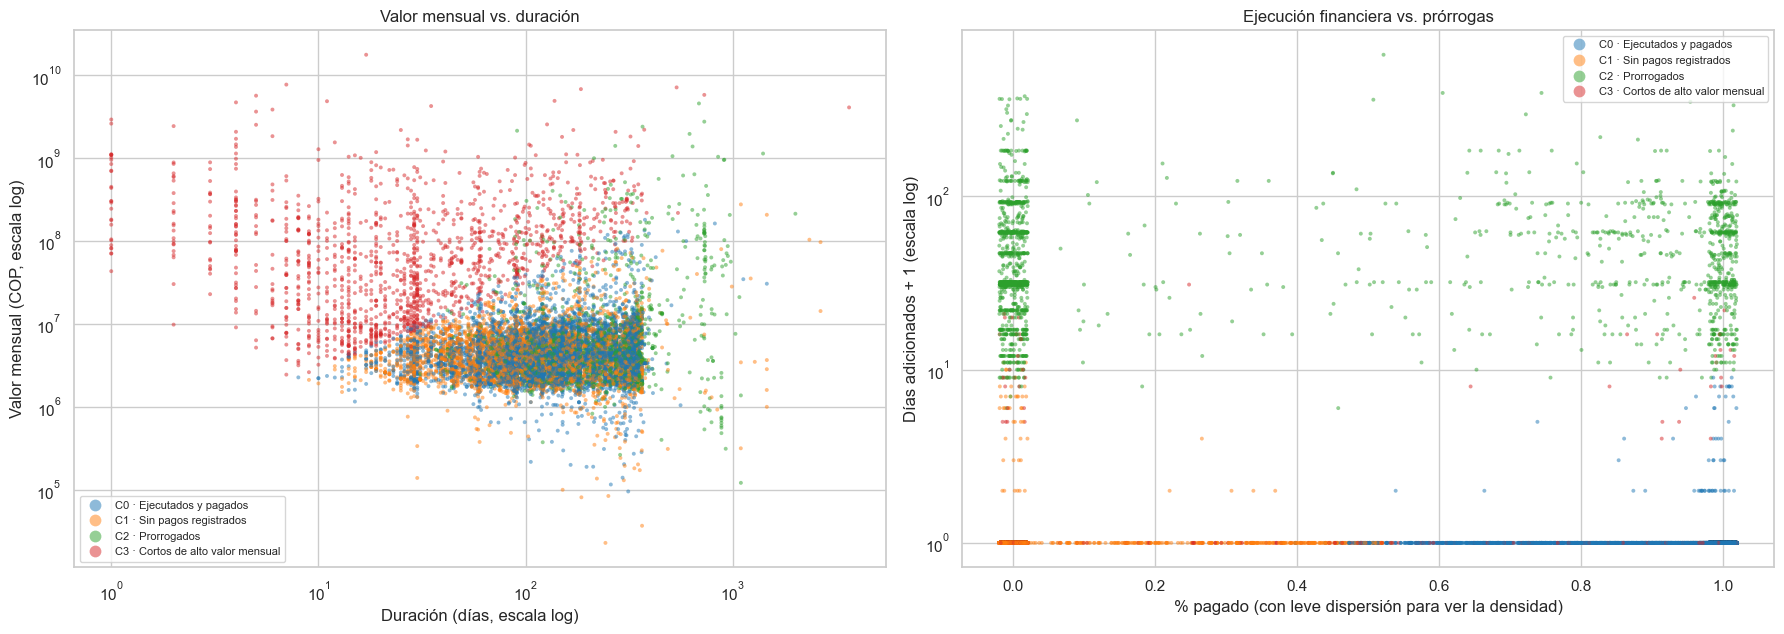

In [28]:
muestra_v = df.iloc[idx_v]
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
sns.scatterplot(data=muestra_v, x='duracion_dias', y='valor_mensual', hue='cluster_nombre',
                hue_order=list(NOMBRE_CLUSTER.values()), palette=colores, s=8, alpha=0.5, linewidth=0, ax=axes[0])
axes[0].set(xscale='log', yscale='log', xlabel='Duración (días, escala log)', ylabel='Valor mensual (COP, escala log)',
            title='Valor mensual vs. duración')
jitter = np.random.RandomState(SEED).uniform(-0.02, 0.02, len(muestra_v))
sns.scatterplot(x=muestra_v['pct_pagado'] + jitter, y=muestra_v['dias_adicionados'] + 1, hue=muestra_v['cluster_nombre'],
                hue_order=list(NOMBRE_CLUSTER.values()), palette=colores, s=8, alpha=0.5, linewidth=0, ax=axes[1])
axes[1].set(yscale='log', xlabel='% pagado (con leve dispersión para ver la densidad)', ylabel='Días adicionados + 1 (escala log)',
            title='Ejecución financiera vs. prórrogas')
for ax in axes:
    ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

### 10.3 Distribución de cada variable por cluster

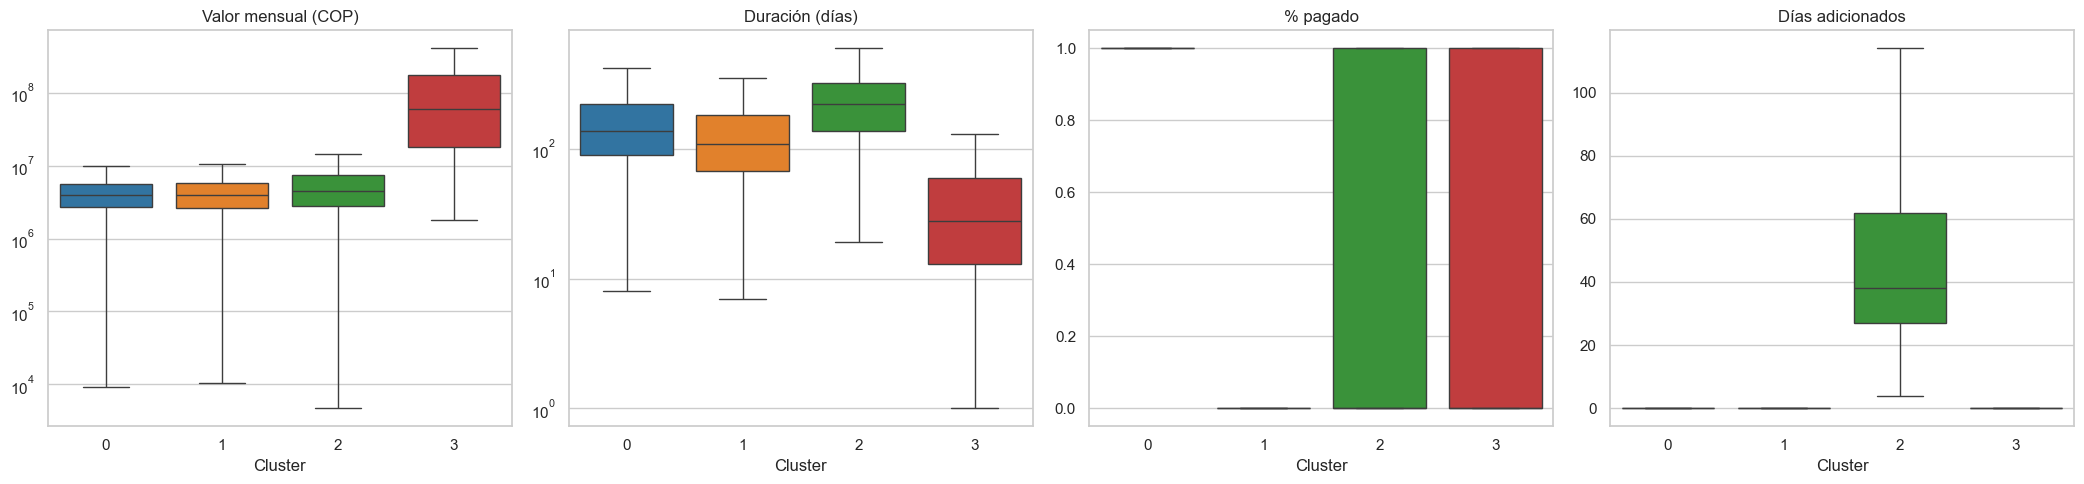

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
cajas = [('valor_mensual', 'Valor mensual (COP)', True), ('duracion_dias', 'Duración (días)', True),
         ('pct_pagado', '% pagado', False), ('dias_adicionados', 'Días adicionados', False)]
for ax, (col, titulo, log) in zip(axes, cajas):
    sns.boxplot(data=df, x='cluster', y=col, hue='cluster', palette=colores, legend=False, showfliers=False, ax=ax)
    ax.set(title=titulo, xlabel='Cluster', ylabel='')
    if log:
        ax.set_yscale('log')
plt.tight_layout()
plt.show()

### 10.4 Tamaño de los clusters y mapa de calor de los centroides

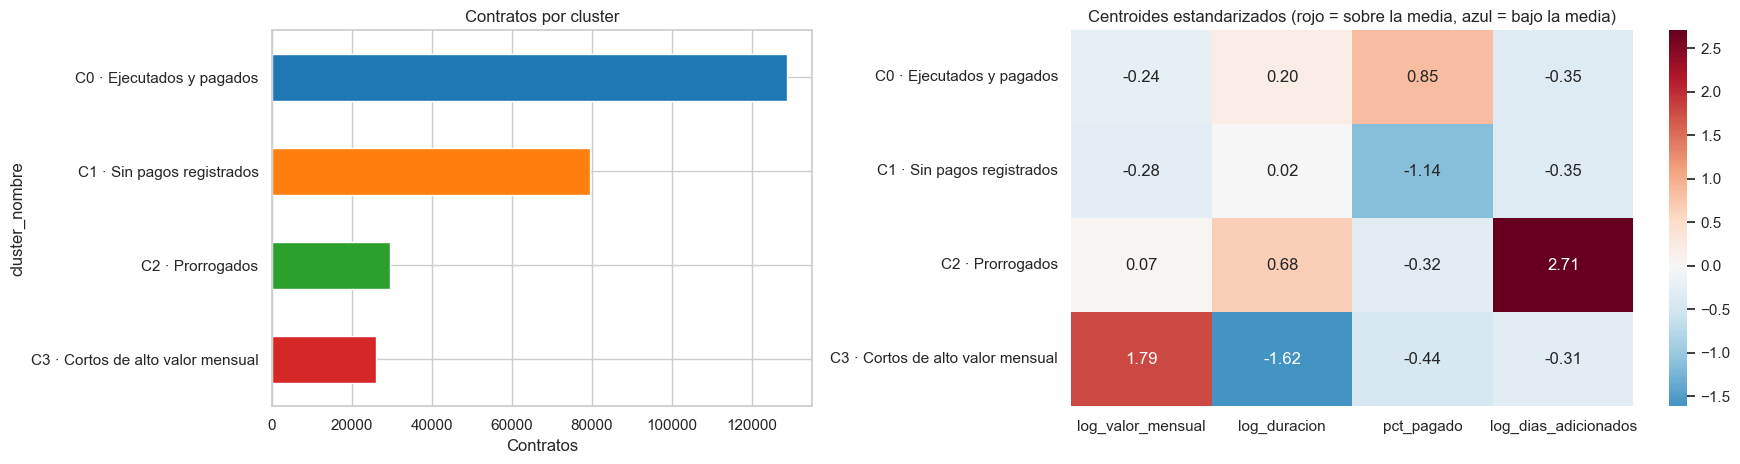

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8), gridspec_kw={'width_ratios': [1, 1.3]})
tamanos.plot.barh(ax=axes[0], color=colores)
axes[0].set(title='Contratos por cluster', xlabel='Contratos')
axes[0].invert_yaxis()
sns.heatmap(pd.DataFrame(centroides_std, columns=VARIABLES_MODELO, index=list(NOMBRE_CLUSTER.values())),
            annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Centroides estandarizados (rojo = sobre la media, azul = bajo la media)')
plt.tight_layout()
plt.show()

## 11. Caracterización e interpretación de cada cluster
### 11.1 Perfil cuantitativo (variables del modelo y variables externas)
Se usan medianas para los montos, porque son robustas frente a los valores extremos, y porcentajes para las categóricas. Las variables externas **no** se usaron para formar los grupos.

In [31]:
perfil = df.groupby('cluster_nombre').agg(
    contratos=('cluster', 'size'),
    valor_total_mediano_mill=('valor_del_contrato', lambda s: s.median() / 1e6),
    valor_mensual_mediano_mill=('valor_mensual', lambda s: s.median() / 1e6),
    duracion_mediana_dias=('duracion_dias', 'median'),
    pct_pagado_medio=('pct_pagado', lambda s: s.mean() * 100),
    pct_prorrogados=('prorrogado', lambda s: s.mean() * 100),
    dias_adicionados_medio=('dias_adicionados', 'mean'),
    pct_persona_juridica=('tipo_contratista', lambda s: (s == 'Persona jurídica').mean() * 100),
    pct_contratacion_directa=('modalidad_grupo', lambda s: (s == 'Contratación directa').mean() * 100),
    pct_prestacion_servicios=('tipo_de_contrato', lambda s: (s == 'Prestación de servicios').mean() * 100),
    pct_cerrado_o_terminado=('estado_contrato', lambda s: s.isin(['Cerrado', 'Terminado']).mean() * 100),
    pct_en_ejecucion=('estado_contrato', lambda s: (s == 'En ejecución').mean() * 100),
    pct_orden_nacional=('orden', lambda s: (s == 'Nacional').mean() * 100),
    mes_firma_promedio=('mes_firma', 'mean'),
).reindex(NOMBRE_CLUSTER.values())
perfil.insert(1, 'pct_contratos', perfil['contratos'] / perfil['contratos'].sum() * 100)
perfil.T.round(2)

cluster_nombre,C0 · Ejecutados y pagados,C1 · Sin pagos registrados,C2 · Prorrogados,C3 · Cortos de alto valor mensual
contratos,"128,599.000","79,541.000","29,599.000","26,097.000"
pct_contratos,48.740,30.150,11.220,9.890
valor_total_mediano_mill,17.990,13.800,30.000,40.900
valor_mensual_mediano_mill,4.010,3.960,4.480,59.970
duracion_mediana_dias,136.000,109.000,220.000,28.000
pct_pagado_medio,96.180,2.480,41.680,40.710
pct_prorrogados,0.730,0.990,100.000,2.880
dias_adicionados_medio,0.020,0.050,53.370,0.340
pct_persona_juridica,6.630,8.880,17.640,66.320
pct_contratacion_directa,88.610,76.120,62.710,33.180


### 11.2 Modalidad, tipo de contrato y segmento UNSPSC por cluster

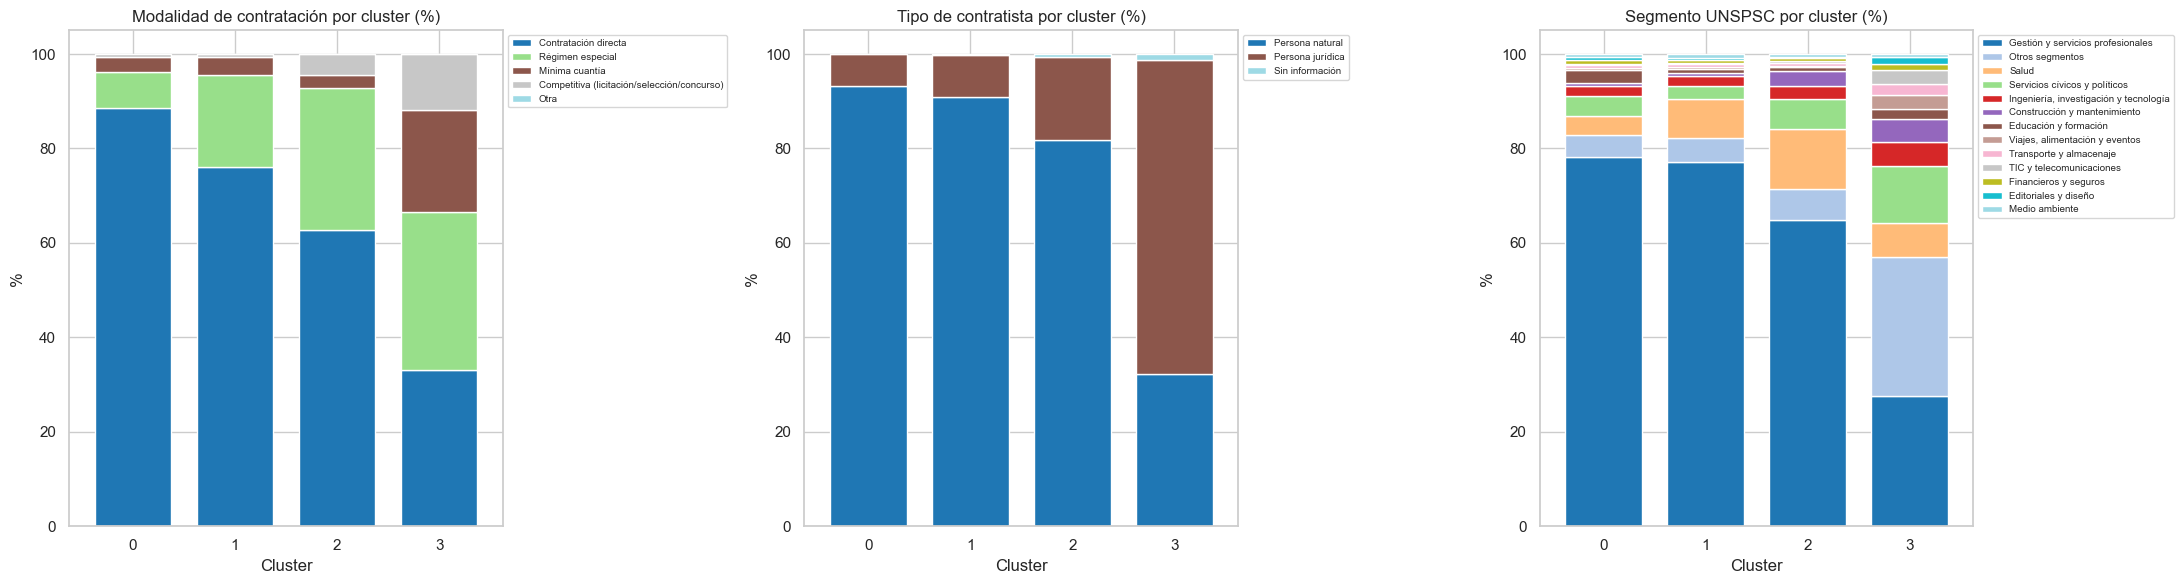

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for ax, col, titulo in [(axes[0], 'modalidad_grupo', 'Modalidad de contratación'),
                        (axes[1], 'tipo_contratista', 'Tipo de contratista'),
                        (axes[2], 'segmento_unspsc', 'Segmento UNSPSC')]:
    tabla = pd.crosstab(df['cluster'], df[col], normalize='index') * 100
    tabla = tabla[tabla.sum().sort_values(ascending=False).index]
    tabla.plot.bar(stacked=True, ax=ax, colormap='tab20', width=0.75)
    ax.set(title=f'{titulo} por cluster (%)', xlabel='Cluster', ylabel='%')
    ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [33]:
for col in ['tipo_de_contrato', 'modalidad_grupo', 'segmento_unspsc', 'estado_contrato', 'sector']:
    print(f'=== {col}: 3 categorías más frecuentes por cluster ===')
    for c in range(K_OPTIMO):
        top = df.loc[df['cluster'] == c, col].value_counts(normalize=True).head(3) * 100
        print(f'  {NOMBRE_CLUSTER[c]:38s} ' + ' | '.join(f'{k} ({v:.1f}%)' for k, v in top.items()))
    print()

=== tipo_de_contrato: 3 categorías más frecuentes por cluster ===
  C0 · Ejecutados y pagados              Prestación de servicios (94.2%) | Decreto 092 de 2017 (1.7%) | Suministros (1.4%)
  C1 · Sin pagos registrados             Prestación de servicios (89.2%) | Decreto 092 de 2017 (5.0%) | Otro (2.1%)
  C2 · Prorrogados                       Prestación de servicios (83.0%) | Otro (7.3%) | Decreto 092 de 2017 (2.3%)
  C3 · Cortos de alto valor mensual      Prestación de servicios (43.4%) | Otro (16.5%) | Decreto 092 de 2017 (11.9%)

=== modalidad_grupo: 3 categorías más frecuentes por cluster ===
  C0 · Ejecutados y pagados              Contratación directa (88.6%) | Régimen especial (7.6%) | Mínima cuantía (3.1%)
  C1 · Sin pagos registrados             Contratación directa (76.1%) | Régimen especial (19.4%) | Mínima cuantía (3.7%)
  C2 · Prorrogados                       Contratación directa (62.7%) | Régimen especial (30.0%) | Competitiva (licitación/selección/concurso) (4.4%)
  C3

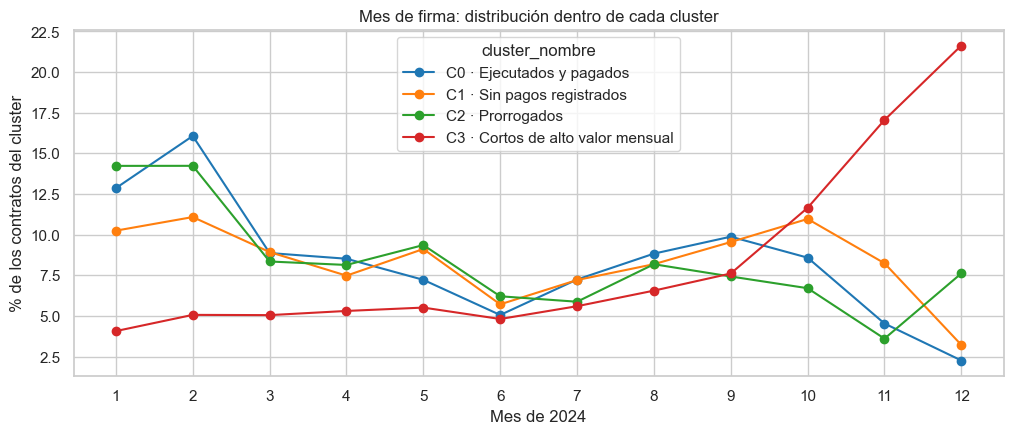

In [34]:
fig, ax = plt.subplots(figsize=(12, 4.5))
(pd.crosstab(df['mes_firma'], df['cluster_nombre'], normalize='columns') * 100)[list(NOMBRE_CLUSTER.values())].plot(
    ax=ax, color=colores, marker='o')
ax.set(title='Mes de firma: distribución dentro de cada cluster', xlabel='Mes de 2024', ylabel='% de los contratos del cluster',
       xticks=range(1, 13))
plt.show()

In [35]:
# Proporciones a partir de la codificación one-hot (resumen compacto)
(dummies.groupby(df['cluster_nombre']).mean() * 100).reindex(NOMBRE_CLUSTER.values()).T.round(1)

cluster_nombre,C0 · Ejecutados y pagados,C1 · Sin pagos registrados,C2 · Prorrogados,C3 · Cortos de alto valor mensual
mod_Competitiva (licitación/selección/concurso),0.700,0.700,4.400,11.800
mod_Contratación directa,88.600,76.100,62.700,33.200
mod_Mínima cuantía,3.100,3.700,2.900,21.500
mod_Otra,0.000,0.000,0.000,0.000
mod_Régimen especial,7.600,19.400,30.000,33.400
contratista_Persona jurídica,6.600,8.900,17.600,66.300
contratista_Persona natural,93.300,90.900,81.700,32.300
contratista_Sin información,0.100,0.200,0.600,1.300
estado_Aprobado,0.000,1.700,0.000,1.700
estado_Cedido,0.500,0.500,0.000,0.000


### 11.3 Interpretación de cada cluster

| Cluster | Tamaño | Contrato típico (medianas) | Rasgos que lo distinguen |
|---|---|---|---|
| **C0 · Ejecutados y pagados** | ≈ 48,7 % | 4,0 M COP/mes · 136 días · 18 M COP en total · 96 % pagado | 93 % personas naturales, 89 % contratación directa, 94 % prestación de servicios, 71 % cerrado o terminado |
| **C1 · Sin pagos registrados** | ≈ 30,1 % | 4,0 M COP/mes · 109 días · 14 M COP en total · **2 % pagado** | El mismo perfil de C0, pero sin pagos reportados. Más régimen especial (19 %) y más del sector salud (20 %) |
| **C2 · Prorrogados** | ≈ 11,2 % | 4,5 M COP/mes · **220 días** · 30 M COP en total · **53 días adicionados** de media | 100 % con prórroga, 96 % en estado "Modificado", 30 % régimen especial, 29 % del sector salud |
| **C3 · Cortos de alto valor mensual** | ≈ 9,9 % | **60 M COP/mes** · **28 días** · 41 M COP en total | **66 % personas jurídicas**, solo 33 % contratación directa, 21 % mínima cuantía, 12 % modalidades competitivas, más firmas en el segundo semestre |

**C0 · Ejecutados y pagados: la prestación de servicios típica que completó su ciclo.** Casi la mitad de los contratos es una persona natural contratada directamente por unos 4 millones al mes durante 4 o 5 meses, como profesional o en apoyo a la gestión. El contrato se pagó casi completo y no se prorrogó. Es el "contrato estándar" del Estado colombiano.

**C1 · Sin pagos registrados: un hallazgo de calidad del reporte.** Económicamente es igual a C0, con el mismo valor mensual y el mismo tipo de contratista. La diferencia es que **no tiene pagos registrados en SECOP II**. Cerca del 45 % sigue en ejecución, pero otro porcentaje importante figura como cerrado o terminado **sin ningún pago reportado**. No es un tipo distinto de contrato, sino un vacío de información: muchas entidades, sobre todo hospitales y empresas sociales del Estado en régimen especial, no registran los pagos en la plataforma. Para SEIA es una **alerta de transparencia**: el campo `valor_pagado` no se debe usar como medida de ejecución sin validarlo.

**C2 · Prorrogados: contratos más largos que se extendieron.** Todos tuvieron prórroga (unos 53 días en promedio), son los de mayor duración (unos 7 meses) y casi todos están en estado "Modificado", lo que es coherente porque una prórroga es una modificación contractual. Tienen más peso en salud y en régimen especial. Para SEIA indican **necesidades recurrentes**: un contrato que se prorroga suele anticipar un nuevo proceso de contratación para el mismo servicio.

**C3 · Cortos de alto valor mensual: compras y servicios a empresas.** Es el único grupo donde **predominan las personas jurídicas** (2 de cada 3) y los procesos **no** son mayoritariamente de contratación directa: aparecen la mínima cuantía, la selección abreviada y la licitación. Es el grupo más diverso en tipo de contrato y en segmento UNSPSC (incluye TIC, construcción, transporte y eventos). Son compras puntuales de alto valor por mes y corta duración, más frecuentes en el segundo semestre. **Es el segmento más relevante para una empresa proveedora como MGD Bitforge S.A.S.**: ahí están los procesos competitivos en los que una empresa puede presentar oferta.

**Validación externa.** El modelo solo vio 4 variables numéricas. Aun así, los grupos se diferencian con claridad en variables que **nunca recibió**: el porcentaje de personas jurídicas va del 7 % al 66 %, el estado "Modificado" aparece en el 96 % de C2, y también cambian la modalidad y el mes de firma. Esto indica que la segmentación captura **patrones reales** de la contratación pública y no es un artefacto del algoritmo.

## 12. Limitaciones y posibles errores
1. **Calidad del reporte en SECOP II.** `pct_pagado` depende de que la entidad registre los pagos, y el cluster C1 es en buena parte consecuencia de ese vacío. También hay errores de digitación en los valores, como un contrato de 6,45 × 10¹⁵ COP. Los imposibles se filtraron, pero los errores "plausibles" (un cero de más, por ejemplo) no se pueden detectar sin otra fuente.
2. **Los datos están vivos.** El endpoint se actualiza a diario. Al reejecutar el notebook pueden cambiar levemente los conteos y las métricas, y los contratos que siguen en ejecución pueden pasar de C1 a C0 cuando se reporten sus pagos. La copia en `datos_secop/` permite repetir exactamente el mismo análisis.
3. **Alcance de la muestra.** Es una muestra sistemática del 30 % de los contratos firmados en 2024. No se verificó si los mismos 4 perfiles aparecen en otros años, y hay estacionalidad: enero y febrero tienen más contratación de personal.
4. **Supuestos de K-Means.** Asume grupos más o menos esféricos y de varianza parecida. Los datos tienen masas de valores repetidos (0 % y 100 % pagado, 0 días adicionados) y transiciones continuas, por eso el silhouette es moderado (≈ 0,45) y el grupo C3 es heterogéneo (silhouette ≈ 0,12).
5. **Las decisiones de diseño influyen en el resultado.** La elección de las variables, el logaritmo, la estandarización (que da el mismo peso a las 4 variables) y los umbrales de los filtros cambian los grupos. Otras decisiones razonables producirían otra segmentación.
6. **Valor mensual en contratos muy cortos.** En contratos de 1 a 5 días, dividir por la duración infla el valor mensual, y eso los empuja hacia C3 aunque su valor total sea bajo.
7. **Categóricas fuera del modelo.** La decisión fue intencional (ver 4.5), pero significa que la modalidad o el tipo de contratista no participan en la formación de los grupos. Con K-Prototypes se podrían incluir.
8. **Solución aproximada.** MiniBatch K-Means no garantiza el óptimo de K-Means. Se mitigó con 10 inicializaciones y comparando con K-Means completo, que dio métricas iguales.
9. **No existe una verdad de referencia.** Los nombres de los clusters son una interpretación del analista basada en los perfiles. Las métricas internas miden compacidad y separación, no si los grupos son "correctos" para el negocio.

## 13. Conclusiones
- Se construyó un modelo de **aprendizaje no supervisado** sobre **≈ 264.000 contratos reales de SECOP II** (2024), la misma fuente que usa SEIA, **sin ninguna variable objetivo**. Se usaron 4 variables numéricas derivadas: valor mensual, duración, % pagado y días adicionados.
- La preparación incluyó conversión de tipos, imputación de fechas, una categoría explícita para los faltantes categóricos, verificación de duplicados, filtrado de registros imposibles (1,2 %), agrupación y codificación de categóricas, transformación logarítmica y estandarización.
- **MiniBatch K-Means** fue la mejor opción: tiene la calidad de K-Means a una fracción del costo, y supera con claridad a Gaussian Mixture y a DBSCAN en estos datos.
- **k = 4** quedó respaldado por el método del codo, el mínimo de Davies-Bouldin, el máximo de Calinski-Harabasz y un Silhouette prácticamente empatado con su máximo.
- Las métricas del modelo final, **Silhouette ≈ 0,45, Davies-Bouldin ≈ 0,94 y Calinski-Harabasz ≈ 144.000**, indican una estructura razonable, con grupos más separados que dispersos.
- Los cuatro segmentos tienen una lectura clara: **(C0) prestación de servicios ejecutada y pagada**, **(C1) contratos sin pagos registrados**, que revelan un vacío de reporte, **(C2) contratos prorrogados** y **(C3) compras cortas de alto valor con empresas**. Se diferencian con fuerza en variables que el modelo no vio, lo que respalda que los patrones son reales.
- **Aporte a SEIA:** C3 concentra los procesos con empresas y modalidades competitivas, donde está la oportunidad comercial del portafolio. C2 anticipa necesidades recurrentes. C1 advierte que la ejecución financiera reportada no es confiable sin validarla.
- **Trabajo futuro:** probar K-Prototypes para incluir las variables categóricas, incorporar las adiciones en valor, repetir el análisis con otros años para comprobar que los perfiles se mantienen, y guardar la etiqueta de cluster en la tabla `procesos_secop` de SEIA.